# Baseline fire-detection experiments

This notebook compares four tabular classifiers and records the reasoning behind a chronological comparison and an exploratory calibration experiment. The target is a **qualifying satellite fire detection in one grid cell on one day**. Same-day retrospective results do not establish future-fire forecasting performance.

## Experiment overview

| Section | Purpose | Training | Evaluation |
| --- | --- | --- | --- |
| 1. Setup | Load the current exports and define predictors | No model fitting | No scoring |
| 2. Full-training baseline | Evaluate fixed models using all available training years | 2020–2024 | 2025 |
| 3. Label distribution | Understand rarity and annual differences | Inspect 2020–2024 labels | No model scoring |
| 4. Paper-aligned baseline | Establish a comparison on the paper's years | 2020–2023 | 2024 |
| 5. Exploratory calibration | Test whether isotonic changes probability quality | Fixed section 4 models; calibrate Jan–Jun 2024 | Jul–Dec 2024 |

Run cells in order. Section 2 contains the only full-training fit; section 4 deliberately fits different model instances on fewer years for comparison with the paper. Section 5 changes probabilities from section 4 and does not update section 2.

2025 outcomes have already been inspected, so section 2 is a previously viewed evaluation, not an untouched final test. Do not tune against it. The recorded runs remain visible; interpretations must be updated if inputs or model settings change.

## 1. Setup: load data and define predictors

Run preprocessing through section 9 to generate the named Parquet exports. The training export covers 2020–2024 and the separate evaluation export covers 2025. Continuous predictors carry scaling fitted on 2020–2024; section 4 refits that scaling for its earlier training cutoff.

### 1.1 Load the exported partitions

In [1]:
import pandas as pd
from peatguard.study import find_root

ROOT = find_root()
DATA_DIR = ROOT / "data/interim/model_table"

train = pd.read_parquet(DATA_DIR / "train_2020_2024.parquet")
test = pd.read_parquet(DATA_DIR / "test_2025.parquet")

print(f"Training: {len(train):,} rows (2020–2024)")
print(f"Test: {len(test):,} rows (2025)")


Training: 6,416,424 rows (2020–2024)
Test: 1,281,880 rows (2025)


### 1.2 Separate predictors and labels

The development experiment below creates its own training and validation arrays from the training export.

In [2]:
from peatguard.datasets import PREDICTORS

feature_columns = PREDICTORS
X_train = train.loc[:, feature_columns]
y_train = train["fire_detected"]
X_test = test.loc[:, feature_columns]
y_test = test["fire_detected"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (6416424, 21)
X_test: (1281880, 21)


## 2. Full-training baseline: train 2020–2024, evaluate 2025

**Question:** What do the four fixed baseline classifiers achieve using all available training years?

Fit Logistic Regression, LightGBM, XGBoost, and Random Forest once using the 2020–2024 export. Evaluate raw, uncalibrated probabilities on 2025 with fixed settings; do not use these outcomes for further model or threshold selection.

This is the extended experiment. The paper-aligned comparison uses different years in section 4, so its scores are not directly comparable. Isotonic calibration is explored separately in section 5 and is not part of this full-training baseline.

### 2.1 Import the model and evaluation tools

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay,
)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

### 2.2 Fit the four models

Use the features loaded in section 1 with their original training-fitted scaling. Fit fresh models on all of 2020–2024 and retain raw 2025 probabilities for both evaluation tables.

In [4]:
# Reuse section 1 data; the development scaler is not applied here.
final_train = train
final_test = test
final_train_dates = pd.to_datetime(final_train["acq_date"])
final_test_dates = pd.to_datetime(final_test["acq_date"])
assert final_train_dates.notna().all() and final_test_dates.notna().all()
assert final_train_dates.between("2020-01-01", "2024-12-31").all()
assert final_test_dates.between("2025-01-01", "2025-12-31").all()
assert final_train_dates.max() < final_test_dates.min()

X_final_train = X_train
y_final_train = y_train
X_final_test = X_test
y_final_test = y_test
assert y_final_train.nunique() == 2 and y_final_test.nunique() == 2

print(f"Training 2020–2024: {len(y_final_train):,} rows; {int(y_final_train.sum()):,} positive cell-days.")
print(f"Evaluation 2025: {len(y_final_test):,} rows; {int(y_final_test.sum()):,} positive cell-days.")

final_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "LightGBM": LGBMClassifier(random_state=42),
    "XGBoost": XGBClassifier(tree_method="hist", random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
}
final_probabilities = {}
for name, model in final_models.items():
    print(f"Fitting {name}...", flush=True)
    model.fit(X_final_train, y_final_train)
    final_probabilities[name] = model.predict_proba(X_final_test)[:, 1]
print("Final baseline fits complete. No calibration or test-based tuning applied.")

Training 2020–2024: 6,416,424 rows; 1,009 positive cell-days.
Evaluation 2025: 1,281,880 rows; 88 positive cell-days.
Fitting Logistic Regression...
Fitting LightGBM...
[LightGBM] [Info] Number of positive: 1009, number of negative: 6415415
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.035620 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1038
[LightGBM] [Info] Number of data points in the train set: 6416424, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.000157 -> initscore=-8.757499
[LightGBM] [Info] Start training from score -8.757499
Fitting XGBoost...
Fitting Random Forest...
Final baseline fits complete. No calibration or test-based tuning applied.


### 2.3 Compare probability error, ranking, and confusion counts

ROC–AUC measures ranking, not accuracy. Average precision is shown relative to the test prevalence, and Brier error relative to a constant probability estimated from training (baseline = 100). Baseline-relative scores do not imply reliable alerts. Confusion matrices use a fixed 0.5 threshold; the next table examines fixed target alert volumes.

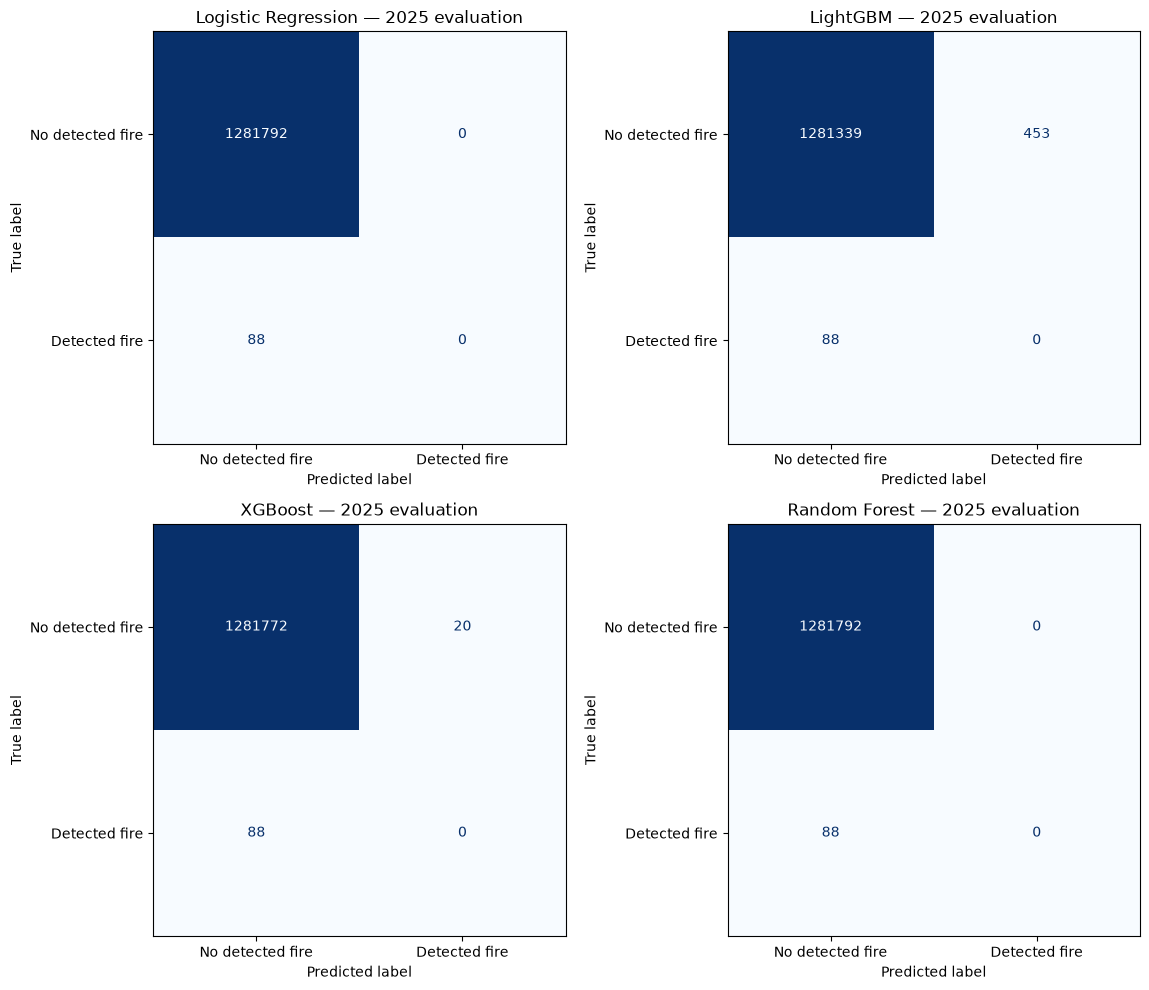

,Model,ROC–AUC,Average precision / chance,Brier error (baseline = 100),Positive cell-days found at 0.5,False alarms at 0.5,Positive cell-days missed at 0.5
0,Logistic Regression,0.773,2.58,100.02,0,0,88
1,LightGBM,0.808,37.48,590.55,0,453,88
2,XGBoost,0.637,61.97,121.58,0,20,88
3,Random Forest,0.847,24.35,103.13,0,0,88


In [5]:
final_constant = np.full(len(y_final_test), y_final_train.mean())
final_baseline_brier = brier_score_loss(y_final_test, final_constant)
final_metrics = []
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, scores) in zip(axes.flat, final_probabilities.items()):
    predictions = scores >= 0.5
    tn, fp, fn, tp = confusion_matrix(y_final_test, predictions, labels=[0, 1]).ravel()
    final_metrics.append({
        "Model": name,
        "ROC–AUC": roc_auc_score(y_final_test, scores),
        "Average precision / chance": average_precision_score(y_final_test, scores) / y_final_test.mean(),
        "Brier error (baseline = 100)": 100 * brier_score_loss(y_final_test, scores) / final_baseline_brier,
        "Positive cell-days found at 0.5": int(tp),
        "False alarms at 0.5": int(fp),
        "Positive cell-days missed at 0.5": int(fn),
    })
    ConfusionMatrixDisplay.from_predictions(
        y_final_test, predictions, labels=[0, 1],
        display_labels=["No detected fire", "Detected fire"],
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
    )
    ax.set_title(f"{name} — 2025 evaluation")
fig.tight_layout()
plt.show()
final_metrics_table = pd.DataFrame(final_metrics)
display(final_metrics_table.style.format({
    "ROC–AUC": "{:.3f}",
    "Average precision / chance": "{:.2f}",
    "Brier error (baseline = 100)": "{:.2f}",
    "Positive cell-days found at 0.5": "{:,.0f}",
    "False alarms at 0.5": "{:,.0f}",
    "Positive cell-days missed at 0.5": "{:,.0f}",
}))

### 2.4 Count detection outcomes at predefined alert volumes

Alert targets of 100, 1,000, and 10,000 are descriptive comparisons across the entire 2025 year, not operational daily budgets or thresholds selected for deployment. All tied scores are included, so compare actual alert counts. A false alarm means no qualifying recorded satellite detection, not confirmed absence of fire.

In [6]:
final_alert_results = []
final_actual_fire = y_final_test.to_numpy() == 1
final_positive_count = int(final_actual_fire.sum())
for name, scores in final_probabilities.items():
    for target_alerts in [100, 1_000, 10_000]:
        k = min(target_alerts, len(scores))
        cutoff = np.partition(scores, len(scores) - k)[len(scores) - k]
        alerts = scores >= cutoff
        found = int((alerts & final_actual_fire).sum())
        final_alert_results.append({
            "Model": name,
            "Target alerts": target_alerts,
            "Actual alerts": int(alerts.sum()),
            "Positive cell-days found": found,
            "False alarms": int(alerts.sum()) - found,
            "Positive cell-days missed": final_positive_count - found,
        })
print(f"2025: {final_positive_count:,} recorded positive cell-days out of {len(y_final_test):,} location-days.")
final_alert_table = pd.DataFrame(final_alert_results)
display(final_alert_table.style.format(thousands=","))

2025: 88 recorded positive cell-days out of 1,281,880 location-days.


,Model,Target alerts,Actual alerts,Positive cell-days found,False alarms,Positive cell-days missed
0,Logistic Regression,100,100,0,100,88
1,Logistic Regression,"1,000","1,000",0,"1,000",88
2,Logistic Regression,"10,000","10,000",0,"10,000",88
3,LightGBM,100,251,0,251,88
4,LightGBM,"1,000","1,009",9,"1,000",79
5,LightGBM,"10,000","10,008",28,"9,980",60
6,XGBoost,100,101,3,98,85
7,XGBoost,"1,000","1,000",10,990,78
8,XGBoost,"10,000","10,000",23,"9,977",65
9,Random Forest,100,100,0,100,88


### 2.5 Final interpretation — completed run

The fixed models were trained on 6,416,424 rows from 2020–2024, including 1,009 positive cell-days. The 2025 evaluation contains 1,281,880 rows and 88 positive cell-days.

| Model | ROC–AUC | Brier error (constant baseline = 100) | Actual alerts near target 1,000 | Positive cell-days found | False alarms |
| --- | ---: | ---: | ---: | ---: | ---: |
| Logistic Regression | 0.773 | 100.02 | 1,000 | 0 | 1,000 |
| LightGBM | 0.808 | 590.55 | 1,009 | 9 | 1,000 |
| XGBoost | 0.637 | 121.58 | 1,000 | 10 | 990 |
| Random Forest | 0.847 | 103.13 | 1,000 | 5 | 995 |

Random Forest has the highest overall ROC–AUC, while XGBoost has the highest average precision and finds the most positives at the roughly 1,000-alert budget. These metrics evaluate different parts of the ranking and need not select the same model. None of the models finds a positive at the fixed 0.5 threshold; none beats the constant baseline on Brier score. The high false-alarm burden does not support dependable standalone alerts.

**Full-training baseline complete.** These findings describe the fixed configurations and this reconstruction; they do not establish that the data are unusable or predict the performance of the paper's spatial and temporal model. The following sections explain the label distribution, establish the paper-aligned **2020–2023 → 2024** comparison, and explore calibration. This section's 2025 results are a separate extended experiment and are not directly comparable to the paper's 2024 scores. No further tuning against 2025 is planned.

This table records the completed run; revise the interpretation if data, configurations, or outputs are changed.

## 3. Inspect the rarity and distribution of detections

**Why inspect the labels?** Positive detections are rare, so accuracy and a default 0.5 threshold are insufficient for assessing detection usefulness. This does not establish that the dataset is unusable.

The complete training export contains 1,009 positive cell-days among 6,416,424 rows:

| Year | Positive cell-days |
| --- | ---: |
| 2020 | 12 |
| 2021 | 80 |
| 2022 | 32 |
| 2023 | 815 |
| 2024 | 70 |

**Decision:** Include the main 2023 fire activity in base-model training. Do not reserve all of 2023 for calibration. Positive cell-days are not necessarily independent fire events.

### 3.1 Count positive rows in the training export

In [7]:
print("fire_detected | total")
print(len(train[train['fire_detected'] == 1])," | ",  len(train))

fire_detected | total
1009  |  6416424


### 3.2 Inspect annual counts

Historical counting code is retained below. Its filters exclude January 1, and the print loop skips 2020. A complete year-grouped check of the saved training export gave the counts in the table above. The 2025 count is a historical test inspection and does not guide the later split.

In [8]:
train_2020 = (train['acq_date'] > '01-01-2020') & (train['acq_date'] <= '31-12-2020')
train_2021 = (train['acq_date'] > '01-01-2021') & (train['acq_date'] <= '31-12-2021')
train_2022 = (train['acq_date'] > '01-01-2022') & (train['acq_date'] <= '31-12-2022')
train_2023 = (train['acq_date'] > '01-01-2023') & (train['acq_date'] <= '31-12-2023')
train_2024 = (train['acq_date'] > '01-01-2024') & (train['acq_date'] <= '31-12-2024')
test_2025 = (test['acq_date'] > '01-01-2025') & (test['acq_date'] <= '31-12-2025')

train_years = [train_2020, train_2021, train_2022, train_2023, train_2024]

In [9]:
for i in range(1, 5):
    print(f"202{i} fire counts:", train_years[i][train['fire_detected'] == 1].sum())

print("2025 fire counts:", test_2025[test['fire_detected'] == 1].sum())

2021 fire counts: 80
2022 fire counts: 32
2023 fire counts: 815
2024 fire counts: 70
2025 fire counts: 88


## 4. Paper-aligned baseline: train 2020–2023, validate 2024

**Question:** How well do models fitted on earlier years identify recorded detections in 2024?

- Base-model training: **2020–2023**, with 939 positive cell-days.
- Validation: **2024**, with 70 positive cell-days.

These are the paper's main training and evaluation years. Here 2024 is a development comparison, not a new untouched final test; the full replication also requires the paper's spatial and temporal inputs, architecture, and training procedure. Keep the initial experiment separate by using fresh `_dev_model` instances.

### 4.1 Create the development split

In [10]:
dev_dates = pd.to_datetime(train["acq_date"], errors="raise")

dev_train_mask = dev_dates < pd.Timestamp("2024-01-01")
dev_val_mask = dev_dates >= pd.Timestamp("2024-01-01")

X_dev_train = train.loc[dev_train_mask, feature_columns].copy()
y_dev_train = train.loc[dev_train_mask, "fire_detected"].copy()
X_dev_val = train.loc[dev_val_mask, feature_columns].copy()
y_dev_val = train.loc[dev_val_mask, "fire_detected"].copy()

split_summary = pd.DataFrame([
    {"split": "Development training", "start": dev_dates.loc[dev_train_mask].min(),
     "end": dev_dates.loc[dev_train_mask].max(), "rows": len(y_dev_train),
     "fire_positive_rows": int(y_dev_train.sum())},
    {"split": "Validation", "start": dev_dates.loc[dev_val_mask].min(),
     "end": dev_dates.loc[dev_val_mask].max(), "rows": len(y_dev_val),
     "fire_positive_rows": int(y_dev_val.sum())},
])
split_summary["fire_rate_pct"] = 100 * split_summary["fire_positive_rows"] / split_summary["rows"]
display(split_summary)


,split,start,end,rows,fire_positive_rows,fire_rate_pct
0,Development training,2020-01-01,2023-12-31,5131032,939,0.018300
1,Validation,2024-01-01,2024-12-31,1285392,70,0.005446


### 4.2 Refit scaling and create fresh models

Fit continuous-feature scaling on 2020–2023, then apply that same transformation to 2024. Land-cover indicators are unchanged. This adjusts the exported affine scaling for the development split; it does not balance labels or introduce new predictors.

In [11]:
# Fresh models for the development experiment.
from sklearn.preprocessing import MinMaxScaler

# The exports use an unclipped affine min-max transform. Re-scaling their
# continuous columns on 2020–2023 removes dependence on the 2024 ranges.
continuous_columns = [column for column in feature_columns if column.endswith("_scaled")]
dev_scaler = MinMaxScaler()
X_dev_train.loc[:, continuous_columns] = dev_scaler.fit_transform(X_dev_train[continuous_columns])
X_dev_val.loc[:, continuous_columns] = dev_scaler.transform(X_dev_val[continuous_columns])

lr_dev_model = LogisticRegression(max_iter=1000, random_state=42)
lgbm_dev_model = LGBMClassifier(random_state=42)
xgb_dev_model = XGBClassifier(tree_method="hist", random_state=42)
rf_dev_model = RandomForestClassifier(random_state=42, n_jobs=-1)

dev_models = {
    "Logistic Regression": lr_dev_model,
    "LightGBM": lgbm_dev_model,
    "XGBoost": xgb_dev_model,
    "Random Forest": rf_dev_model,
}


### 4.3 Fit models and inspect validation confusion matrices

Fit on 2020–2023 and predict on 2024. These matrices use the default 0.5 threshold; the ranking comparisons below examine other alert volumes.

Fitting Logistic Regression...
Fitting LightGBM...
[LightGBM] [Info] Number of positive: 939, number of negative: 5130093
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018103 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1038
[LightGBM] [Info] Number of data points in the train set: 5131032, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.000183 -> initscore=-8.605819
[LightGBM] [Info] Start training from score -8.605819
Fitting XGBoost...
Fitting Random Forest...


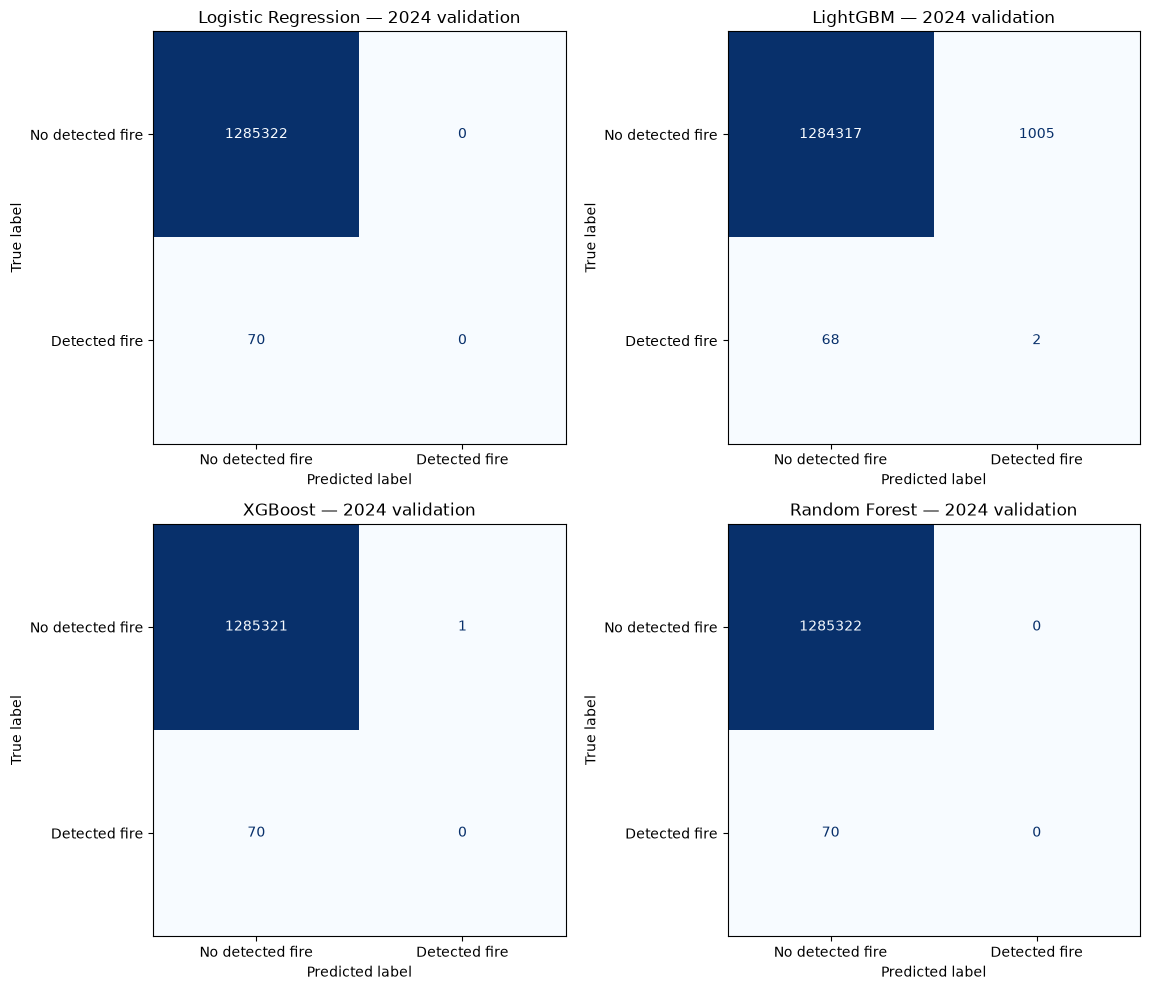

In [12]:
# Fit on 2020–2023 and evaluate on 2024 only.
# These are uncalibrated baselines using the default 0.5 threshold.
dev_predictions = {}
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))

for ax, (model_name, model) in zip(axes.flat, dev_models.items()):
    print(f"Fitting {model_name}...", flush=True)
    model.fit(X_dev_train, y_dev_train)
    y_dev_pred = model.predict(X_dev_val)
    dev_predictions[model_name] = y_dev_pred

    ConfusionMatrixDisplay.from_predictions(
        y_true=y_dev_val,
        y_pred=y_dev_pred,
        labels=[0, 1],
        display_labels=["No detected fire", "Detected fire"],
        ax=ax,
        cmap=plt.cm.Blues,
        colorbar=False,
        values_format="d",
    )
    ax.set_title(f"{model_name} — 2024 validation")

fig.tight_layout()
plt.show()


### 4.4 Compare probability error and ranking

- **Brier error:** constant training-frequency prediction = 100; lower is better. A score near 100 means little improvement over the constant baseline.
- **Average precision / chance:** larger values indicate stronger ranking relative to the positive prevalence. This ratio is not alert precision or a percentage of correct predictions.

In [13]:
# Compare models on 2024. Constant training-frequency prediction = 100.
import numpy as np
from sklearn.metrics import average_precision_score, brier_score_loss

val_probabilities = {
    name: model.predict_proba(X_dev_val)[:, 1]
    for name, model in dev_models.items()
}
baseline_probabilities = np.full(len(y_dev_val), y_dev_train.mean())
baseline_brier = brier_score_loss(y_dev_val, baseline_probabilities)

comparison = []
for name, scores in val_probabilities.items():
    comparison.append({
        "Model": name,
        "Brier error (baseline = 100; lower is better)":
            100 * brier_score_loss(y_dev_val, scores) / baseline_brier,
        "Average precision / chance (higher is better)":
            average_precision_score(y_dev_val, scores) / y_dev_val.mean(),
    })

display(pd.DataFrame(comparison).round(2))


,Model,Brier error (baseline = 100; lower is better),Average precision / chance (higher is better)
0,Logistic Regression,100.03,2.45
1,LightGBM,1510.59,12.67
2,XGBoost,104.85,21.71
3,Random Forest,113.43,13.11


### 4.5 Translate scores into alert counts

Flag the highest-scoring location-days for the entire validation year. A false alarm means no qualifying recorded detection, not confirmed ground-truth absence of fire. Include tied scores and report the actual alert volume.

In [14]:
# Count outcomes when flagging the highest-scoring location-days.
actual_fire = y_dev_val.to_numpy() == 1
total_fires = int(actual_fire.sum())
alert_results = []

for name, scores in val_probabilities.items():
    for target_alerts in [1_000, 10_000, 100_000]:
        k = min(target_alerts, len(scores))
        cutoff = np.partition(scores, len(scores) - k)[len(scores) - k]
        alerts = scores >= cutoff  # Include tied scores rather than break ties arbitrarily.
        found = int((alerts & actual_fire).sum())
        alert_count = int(alerts.sum())

        alert_results.append({
            "Model": name,
            "Target alerts": target_alerts,
            "Actual alerts": alert_count,
            "Fire-positive cell-days found": found,
            "False alarms": alert_count - found,
            "Fire-positive cell-days missed": total_fires - found,
        })

print(f"2024: {total_fires:,} fire-positive cell-days out of {len(actual_fire):,} location-days.")
print("Tied scores can increase actual alerts above the target. Counts cover the whole year.")
display(pd.DataFrame(alert_results).style.format(thousands=","))


2024: 70 fire-positive cell-days out of 1,285,392 location-days.
Tied scores can increase actual alerts above the target. Counts cover the whole year.


,Model,Target alerts,Actual alerts,Fire-positive cell-days found,False alarms,Fire-positive cell-days missed
0,Logistic Regression,"1,000","1,000",0,"1,000",70
1,Logistic Regression,"10,000","10,000",1,"9,999",69
2,Logistic Regression,"100,000","100,000",13,"99,987",57
3,LightGBM,"1,000","1,000",2,998,68
4,LightGBM,"10,000","10,004",7,"9,997",63
5,LightGBM,"100,000","100,004",43,"99,961",27
6,XGBoost,"1,000","1,000",3,997,67
7,XGBoost,"10,000","10,000",16,"9,984",54
8,XGBoost,"100,000","100,000",49,"99,951",21
9,Random Forest,"1,000","1,000",3,997,67


### 4.6 Interpretation and reason for the next experiment

In the recorded run, raw XGBoost had the highest average precision. Its highest-scoring 10,000 validation location-days included 16 of the 70 positives and 9,984 rows without a qualifying detection. None of the models beat the constant baseline on Brier score.

**Decision:** Retain raw XGBoost as a ranking benchmark and test whether isotonic calibration improves probability error. Calibration cannot add missing predictors or guarantee useful alerts. These observations describe the recorded run; inspect the tables again after changing data or model settings.

## 5. Experiment: isotonic probability calibration

**Question:** Can a score-to-probability mapping reduce error on later development observations?

| Role | Period | Positive cell-days |
| --- | --- | ---: |
| Base-model fitting | 2020–2023 | 939 |
| Calibration fitting | January–June 2024 | 9 |
| Calibration evaluation | July–December 2024 | 61 |

The calendar halves are an exploratory choice, not a paper-derived protocol. Only 9 positives support calibration, so estimates may be unstable. All of 2024 has already been inspected during development; this is not an untouched final test. No 2025 outcomes are used in this section.

Isotonic regression changes probability values and can merge scores into ties. Evaluate it on observations not used to fit the mapping. Compare against both a training-frequency constant and a calibration-frequency constant to distinguish score-dependent improvement from a simple frequency adjustment.

### 5.1 Separate calibration fitting from evaluation

Use fixed calendar halves of 2024. Neither half trains the base classifiers. Display the positive counts before fitting calibration.

In [15]:
# Use cached 2024 predictions; the base models do not need retraining.
calibration_dates = pd.to_datetime(train.loc[y_dev_val.index, "acq_date"])
assert calibration_dates.between("2024-01-01", "2024-12-31").all()
calibration_mask = (calibration_dates < "2024-07-01").to_numpy()
calibration_eval_mask = ~calibration_mask

y_calibration = y_dev_val.to_numpy()[calibration_mask]
y_calibration_eval = y_dev_val.to_numpy()[calibration_eval_mask]
assert len(np.unique(y_calibration)) == 2
assert len(np.unique(y_calibration_eval)) == 2

print(f"Calibration, Jan–Jun: {len(y_calibration):,} rows; {int(y_calibration.sum())} positive cell-days.")
print(f"Evaluation, Jul–Dec: {len(y_calibration_eval):,} rows; {int(y_calibration_eval.sum())} positive cell-days.")
print("Exploratory only: calibration has very few positive examples.")


Calibration, Jan–Jun: 639,184 rows; 9 positive cell-days.
Evaluation, Jul–Dec: 646,208 rows; 61 positive cell-days.
Exploratory only: calibration has very few positive examples.


### 5.2 Fit isotonic probability mappings

Reuse cached predictions from the fixed base models. Learn the mappings using January–June labels only.

In [16]:
from sklearn.isotonic import IsotonicRegression

isotonic_calibrators = {}
calibration_eval_probabilities = {}

for name, scores in val_probabilities.items():
    assert len(scores) == len(y_dev_val)
    calibrator = IsotonicRegression(out_of_bounds="clip")
    calibrator.fit(scores[calibration_mask], y_calibration)
    isotonic_calibrators[name] = calibrator
    calibration_eval_probabilities[name] = {
        "Raw": scores[calibration_eval_mask],
        "Isotonic": calibrator.predict(scores[calibration_eval_mask]),
    }

print("Fitted isotonic calibrators for all four models. Base models unchanged.")


Fitted isotonic calibrators for all four models. Base models unchanged.


### 5.3 Evaluate raw and calibrated probabilities

Compare on the same July–December rows. Brier error uses a new baseline and a shorter evaluation period, so compare within this table. Isotonic ties can increase actual alert counts: finding more positives with more alerts is not evidence of better detection at an equal budget.

In [17]:
# Compare probability error and alert counts on Jul–Dec only.
calibration_constant = np.full(len(y_calibration_eval), y_calibration.mean())
calibration_reference_brier = brier_score_loss(y_calibration_eval, calibration_constant)
calibration_comparison = []

# Include both constants: calibration can help simply by changing the base rate.
evaluation_scores = {
    ("Constant", "2020–2023 frequency"): np.full(len(y_calibration_eval), y_dev_train.mean()),
    ("Constant", "Jan–Jun 2024 frequency"): calibration_constant,
}
for name, versions in calibration_eval_probabilities.items():
    for version, scores in versions.items():
        evaluation_scores[(name, version)] = scores

for (name, version), scores in evaluation_scores.items():
    # Same target alert budget, including all ties for honest comparisons.
    k = min(10_000, len(scores))
    cutoff = np.partition(scores, len(scores) - k)[len(scores) - k]
    alerts = scores >= cutoff
    found = int((alerts & (y_calibration_eval == 1)).sum())
    calibration_comparison.append({
        "Model": name,
        "Version": version,
        "Brier error (baseline = 100)": 100 * brier_score_loss(y_calibration_eval, scores) / calibration_reference_brier,
        "Average precision / chance": average_precision_score(y_calibration_eval, scores) / y_calibration_eval.mean(),
        "Actual alerts (target 10,000)": int(alerts.sum()),
        "Positive cell-days found": found,
        "False alarms": int(alerts.sum()) - found,
        "Positive cell-days missed": int(y_calibration_eval.sum()) - found,
    })

print("Jul–Dec evaluation: lower Brier error is better. Baseline = Jan–Jun constant probability.")
print("Ties may greatly expand the alert list; constant predictions flag every row.")
print("Compare only within this table: the earlier tables evaluated the whole of 2024.")
display(pd.DataFrame(calibration_comparison).style.format({
    "Brier error (baseline = 100)": "{:.2f}",
    "Average precision / chance": "{:.2f}",
    "Actual alerts (target 10,000)": "{:,.0f}",
    "Positive cell-days found": "{:,.0f}",
    "False alarms": "{:,.0f}",
    "Positive cell-days missed": "{:,.0f}",
}))


Jul–Dec evaluation: lower Brier error is better. Baseline = Jan–Jun constant probability.
Ties may greatly expand the alert list; constant predictions flag every row.
Compare only within this table: the earlier tables evaluated the whole of 2024.


,Model,Version,Brier error (baseline = 100),Average precision / chance,"Actual alerts (target 10,000)",Positive cell-days found,False alarms,Positive cell-days missed
0,Constant,2020–2023 frequency,100.00,1.00,"646,208",61,"646,147",0
1,Constant,Jan–Jun 2024 frequency,100.00,1.00,"646,208",61,"646,147",0
2,Logistic Regression,Raw,100.02,2.07,"10,000",2,"9,998",59
3,Logistic Regression,Isotonic,100.00,1.82,"142,652",30,"142,622",31
4,LightGBM,Raw,996.50,10.27,"10,002",10,"9,992",51
5,LightGBM,Isotonic,99.97,5.04,"10,738",11,"10,727",50
6,XGBoost,Raw,104.41,15.41,"10,000",15,"9,985",46
7,XGBoost,Isotonic,99.95,9.41,"22,385",25,"22,360",36
8,Random Forest,Raw,112.35,11.10,"10,000",12,"9,988",49
9,Random Forest,Isotonic,99.99,5.14,"23,757",22,"23,735",39


### 5.4 Interpretation of the recorded calibration run

Calibration reduced Brier error, especially for LightGBM, but the calibrated models were approximately equal to the constant baseline. XGBoost's calibrated Brier error was 99.95 against a baseline of 100: a small gain on this evaluation period.

Average precision declined for every model as isotonic mappings introduced ties. XGBoost found 25 positives with 22,385 alerts after calibration, versus 15 positives with 10,000 raw-score alerts. Those unequal alert volumes do not demonstrate improved detection at a fixed budget.

**Conclusion:** This experiment does not establish reliable fire alerts or a robust calibration benefit. The small calibration-positive count and the seasonal difference between the calendar halves limit the conclusion. Reassess these statements if a rerun changes the outputs.

### 5.5 Baseline notebook conclusion

The full-training baseline in section 2 and the paper-aligned baseline in section 4 answer different year-specific questions. The exploratory isotonic experiment does not establish better alerts: it has only nine calibration positives, and ties change actual alert volumes. Its calibrators belong to the section 4 models and are not attached to section 2's refitted models.

**Next stage:** recreate CNN–ConvLSTM in `cnn_conv_lstm.ipynb` using **2020–2023 training → 2024 evaluation**, documenting the published settings and any necessary assumptions. Use section 4 as the tabular comparison on the same years. Further baseline tuning is outside this completed notebook's scope.